<h1>TP Deep Learning - CNN</h1>

Cette troisième séance porte sur la découverte des réseaux de convolutions :
* Retour sur MNIST
* Première architecture convolutionnelle
* Visualisation des filtres
* Utilisation de VGG16, un réseau pré-entrainé
* Visualisation des filtres par maximisation des activations
* Augmentation de données
* Classification du jeu de données Cifar10

<hr/>

Import des premiers packages nécessaires :

In [ ]:
from keras.datasets import cifar10

import numpy as np
import tensorflow as tf
keras = tf.keras
# from tensorflow import keras as keras
from keras.utils import to_categorical
from keras.models import Sequential, Model
from keras.datasets import mnist
from keras.models import Model
from keras.layers import Input, Dense, Concatenate, Flatten, Dropout, Conv2D, MaxPooling2D, BatchNormalization
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input
from keras.preprocessing import image

from keras.src.legacy.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import json
print(keras.__version__)

# !wget https://pageperso.lis-lab.fr/stephane.ayache/cat.jpg
# !wget https://pageperso.lis-lab.fr/stephane.ayache/imagenet_class_index.json

3.15.1


<h2> Chargement des données</h2>

Ici on charge le jeu de données MNIST (les chiffres manuscrits), puis quelques instructions de mise en forme

In [6]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
img_rows, img_cols = 28, 28
nb_classes = 10
nb_samples = len(x_train)
x_train = x_train.reshape(x_train.shape[0], img_rows, img_cols, 1) # (batch, rows, cols, channel)
x_test = x_test.reshape(x_test.shape[0], img_rows, img_cols, 1)
input_shape = (img_rows, img_cols, 1) # shape d'un élément, utile pour keras
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255

Le jeu de données MNIST contient 60000 exemples répartis en 10 classes. Nous allons ici en sélectionner aléatoirement un certain nombre pour accélérer les étapes suivantes.

In [7]:
nb_subsamples = 10000
l_idx = np.random.permutation(list(range(nb_samples)))[:nb_subsamples]

x_train, y_train = x_train[l_idx], y_train[l_idx]

Il est d'abord nécessaire de formater les vecteurs d'étiquettes en <i>one-hot vectors</i> de tailles num_classes. Ces vecteurs contiennent des 0 et un seul 1 par ligne à l'indice correspondant à la classe. Tensorflow/Keras a une fonction pour ça :

In [9]:
y_train2 = to_categorical(y_train, nb_classes)
y_test2 = to_categorical(y_test, nb_classes)
print(y_train[0], y_train2[0]) # affiche une classe et sa représentation one_hot

4 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


Avec Numpy, ça revient à :

In [10]:
y_train2 = np.zeros((nb_subsamples, nb_classes))
y_train2[np.arange(nb_subsamples), y_train] = 1
print(y_train[0], y_train2[0]) # affiche une classe et sa représentation one_hot

4 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


<hr/>
<h1>Keras/Tensorflow</h1>

<h3>Création d'un réseau de neurones</h3>

Avec Keras, Tensorflow propose deux API pour la définition de réseaux de neurones. La plus simple *Sequential* est illustrée dans ce notebook. Elle permet de créer de simples architectures construits comme une séquence de couches.

Pour les architectures plus complexes, la *Graph API* permet de définir un graphe de couches avec plusieurs entrées et sorties. La cellule suivante montre un exemple minimal :



In [11]:
# branche 1
input1 = Input(shape=(392,)) # entrée 1 : vecteur de dimension 392
x1 = Dense(256, activation='relu')(input1)
x1 = Dense(512, activation='relu')(x1)

# branche 2
input2 = Input(shape=(392,)) # entrée 1 : vecteur de dimension 392
x2 = Dense(256, activation='relu')(input2)
x2 = Dense(512, activation='relu')(x2)

# merge and output
x = Concatenate()([x1, x2])
x = Dense(512, activation='relu')(x)
x = Dense(10, activation='softmax')(x)

# instanciate and compile model
model = Model([input1, input2], [x]) # Model(liste d'entrées, liste de sorties)
model.compile(loss=["categorical_crossentropy"], optimizer="adam", metrics=["accuracy"]) # un tableau de losse, une par sortie
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 392)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 392)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    100,608 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │    100,608 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 512)       │    131,584 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 512)       │    131,584 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1024)      │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 512)       │    524,800 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 10)        │      5,130 │ dense_4[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 994,314 (3.79 MB)

 Trainable params: 994,314 (3.79 MB)

 Non-trainable params: 0 (0.00 B)

<h3>Entrainement "haut niveau" de Keras : fit, predict, evaluate</h3>
Keras offre plusieurs niveaux d'implémentations d'une boucle d'apprentissage, le plus heut niveau reprend le modèle de sklearn avec la fonction fit. Comme on le verra à la fin de notebook, fit fonctionne aussi avec des générateurs python, par exmple pour l'augmentation de données.

<h3> Réseau Dense</h3>

Prenons un réseau MLP simple et notez son nombre de paramètres et sa performance obtenue, ils nous serviront de référence. La couche Flatten mise en entrée du réseau sert à vectoriser les images MNIST puisque les couches Dense opèrent uniquement sur des vecteurs.

In [12]:
model1 = Sequential() # API Sequential de Keras pour des réseaux simples
model1.add(Flatten(input_shape=input_shape)) # input_shape est seulement nécessaire sur la première couche
model1.add(Dense(512, activation='relu'))
model1.add(Dropout(0.2))
model1.add(Dense(1024, activation='relu'))
model1.add(Dropout(0.2))
model1.add(Dense(nb_classes, activation='softmax'))
model1.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

print(model1.summary())

loss = model1.fit(x_train, y_train2, batch_size=128, epochs=20, validation_split=0.1, callbacks=[], verbose=1)
score = model1.evaluate(x_test, y_test2, verbose=0)

print("score=", score) # score est un tuple (loss, metric)

c:\Users\felip\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 937,482 (3.58 MB)

 Trainable params: 937,482 (3.58 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.8332 - loss: 0.5670 - val_accuracy: 0.9340 - val_loss: 0.2543
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9373 - loss: 0.2135 - val_accuracy: 0.9480 - val_loss: 0.1542
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9570 - loss: 0.1374 - val_accuracy: 0.9560 - val_loss: 0.1400
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9717 - loss: 0.0939 - val_accuracy: 0.9640 - val_loss: 0.1202
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9759 - loss: 0.0714 - val_accuracy: 0.9630 - val_loss: 0.1213
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9843 - loss: 0.0480 - val_accuracy: 0.9580 - val_loss: 0.1282
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9887 - loss: 0.0380 - val_accuracy: 0.9640 - val_loss: 0.1261
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9909 - loss: 0.0305 - val_accuracy: 0.968

**A Faire :** Evaluez l'architecture à deux entrées définie plus haut sur les données MNIST en séparant en deux vecteurs de tailles 392 les vecteurs MNIST initiaux.

In [13]:
input1 = Input(shape=(392,))
input2 = Input(shape=(392,))

x = Concatenate()([input1, input2])

model1 = Sequential()
model1.add(Flatten())
model1.add(Dense(512, activation='relu'))
model1.add(Dropout(0.2))
model1.add(Dense(1024, activation='relu'))
model1.add(Dropout(0.2))
model1.add(Dense(nb_classes, activation='softmax'))

output = model1(x)

model1 = Model(inputs = [input1, input2], outputs=output)
model1.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

print(model1.summary())

x_train1 = x_train.reshape(-1, 784)[:, :392]
x_train2 = x_train.reshape(-1, 784)[:, 392:]
x_test1 = x_test.reshape(-1, 784)[:, :392]
x_test2 = x_test.reshape(-1, 784)[:, 392:]

loss = model1.fit([x_train1, x_train2], y_train2, batch_size=128, epochs=20, validation_split=0.1, callbacks=[], verbose=1)
score = model1.evaluate([x_test1, x_test2], y_test2, verbose=0)

print("score=", score) # score est un tuple (loss, metric)

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 392)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_4       │ (None, 392)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 784)       │          0 │ input_layer_3[0]… │
│ (Concatenate)       │                   │            │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 10)        │    937,482 │ concatenate_1[0]… │
│ (Sequential)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 937,482 (3.58 MB)

 Trainable params: 937,482 (3.58 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.8343 - loss: 0.5577 - val_accuracy: 0.9270 - val_loss: 0.2325
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9371 - loss: 0.2160 - val_accuracy: 0.9380 - val_loss: 0.1893
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9537 - loss: 0.1428 - val_accuracy: 0.9540 - val_loss: 0.1398
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9739 - loss: 0.0884 - val_accuracy: 0.9530 - val_loss: 0.1514
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9793 - loss: 0.0693 - val_accuracy: 0.9640 - val_loss: 0.1092
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9866 - loss: 0.0462 - val_accuracy: 0.9600 - val_loss: 0.1281
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9887 - loss: 0.0348 - val_accuracy: 0.9530 - val_loss: 0.1620
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9870 - loss: 0.0393 - val_accuracy: 0.962

<h3>Première architecture convolutionnelle</h3>

Créons un nouveau réseau dont les couches Dense (sauf la dernière pour la classification) sont remplacées par des Conv2D, suivis de MaxPooling2D. Notons que la couche "Flatten" n'est pas utilisée en début de réseau, puisque les données du réseau sont supposées 2D. En revanche, la couche Dense en bout de réseau suppose des données d'entrée en 1D.


In [14]:
def simple_cnn():
  model2 = Sequential()
  model2.add(Conv2D(64, kernel_size=(5,5), strides=(1,1), padding='same', activation='relu', input_shape=input_shape))
  model2.add(MaxPooling2D((2,2)))
  model2.add(Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same', activation='relu'))
  model2.add(MaxPooling2D((2,2)))
  model2.add(Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same', activation='relu', kernel_regularizer='l2'))
  model2.add(MaxPooling2D((2,2)))
  model2.add(Flatten()) # Vectorise les features maps pour entrer dans une couche dense
  model2.add(Dropout(0.2))
  model2.add(Dense(nb_classes, activation='softmax'))
  model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
  print(model2.summary())
  return model2

<b>A faire :</b> Expliquez les nombres de paramètres de chaque couche.

Conv2D : num_params = (hauteur x largeur x nombre_d_filtres_d_entree + 1) x nombre_de_filtres

Dense: num_params = (num_params_entree + 1) x num_params_sortie

MaxPooling2D, Flatten et Dropout : ils organisent juste les données. Ils ne participent pas à l' entrainement. 

---

Conv2D : (5 x 5 x 1 + 1) x 64 = 1664

MaxPooling2D (2x2) : 0

Conv2D : (3 x 3 x 64 + 1) x 128 = 73856

MaxPooling2D (2x2) : 0

Conv2D : (3 x 3 x 128 + 1) x 128 = 147584

MaxPooling2D (2x2) : 0

Flatten : 0

Dropout : 0

Dense : (3 x 3 x 128 + 1) x 10 = 11530

<br/>
<hr/>

<h4>Entrainement du réseau</h4>

Appelons maintenant les fonctions fit et evaluate pour entrainer et tester le réseau. Visualisez la courbe d'apprentissage pour vérifier que tout s'apprend bien.

In [15]:
model2 = simple_cnn()
loss = model2.fit(x_train, y_train2, batch_size=128, epochs=20, validation_split=0.1, callbacks=[], verbose=1)
score = model2.evaluate(x_test, y_test2, verbose=0)
print("score=", score)

c:\Users\felip\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,634 (916.54 KB)

 Trainable params: 234,634 (916.54 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - accuracy: 0.7487 - loss: 1.4189 - val_accuracy: 0.9580 - val_loss: 0.5331
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 151ms/step - accuracy: 0.9466 - loss: 0.4526 - val_accuracy: 0.9760 - val_loss: 0.2975
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.9687 - loss: 0.2614 - val_accuracy: 0.9770 - val_loss: 0.1909
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 134ms/step - accuracy: 0.9679 - loss: 0.2027 - val_accuracy: 0.9780 - val_loss: 0.1684
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 12s 166ms/step - accuracy: 0.9736 - loss: 0.1617 - val_accuracy: 0.9670 - val_loss: 0.1596
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 12s 175ms/step - accuracy: 0.9760 - loss: 0.1467 - val_accuracy: 0.9780 - val_loss: 0.1301
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 13s 189ms/step - accuracy: 0.9788 - loss: 0.1335 - val_accuracy: 0.9800 - val_loss: 0.1192
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 144ms/step - accuracy: 0.9808 - loss: 0.1206 - val

**A faire :** Qu'observez-vous ? Comment l'expliquer ?

On observe une amélioration du modèle grâce à une évolution significative des métriques :

Accuracy : 0.7487 → 0.9872

Loss : 1.4189 → 0.0818

Validation loss : 0.5331 → 0.0813

De plus, on peut noter que les accuracies d'entraînement (0.9872), de validation (0.9870) et de test (0.9865) sont très similaires après l'entraînement.

Enfin, on peut conclure que le modèle a bien appris à partir des données et qu'il répond efficacement au problème de classification.

<h3>Implémentation de la boucle d'entrainement</h3>

La seule fonction fit ne permet pas tout, il faut souvent aller plus en détail dans la boucle d'entrainement. Avec Keras, on peut utiliser la fonction train_on_batch :


In [16]:
# reinitialiation du modèle
model2 = simple_cnn()

# boucle d'entrainement
nb_epochs = 20
batch_size = 128
nb_batchs = int(nb_subsamples/batch_size)

# Prepare les batchs avec tf
train_dataset = tf.data.Dataset.from_tensor_slices((x_train, y_train2))
train_dataset = train_dataset.shuffle(buffer_size=1024).batch(batch_size)

for epoch in range(nb_epochs):
  for step, (x, y) in enumerate(train_dataset):
    loss = model2.train_on_batch(x, y)

  # affiche la loss du dernier batch à chaque fin d'epoch
  print("epoch", epoch, "loss=", loss)

score = model2.evaluate(x_test, y_test2, verbose=0)
print("score=", score)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,634 (916.54 KB)

 Trainable params: 234,634 (916.54 KB)

 Non-trainable params: 0 (0.00 B)

None
epoch 0 loss= [0.7342595458030701, 0.9375]
epoch 1 loss= [0.42785361409187317, 0.9375]
epoch 2 loss= [0.138815775513649, 1.0]
epoch 3 loss= [0.09948612749576569, 1.0]
epoch 4 loss= [0.13953423500061035, 0.9375]
epoch 5 loss= [0.12254787981510162, 0.9375]
epoch 6 loss= [0.07355235517024994, 1.0]
epoch 7 loss= [0.39542528986930847, 0.875]
epoch 8 loss= [0.14187029004096985, 1.0]
epoch 9 loss= [0.0708913654088974, 1.0]
epoch 10 loss= [0.055215924978256226, 1.0]
epoch 11 loss= [0.06859032809734344, 1.0]
epoch 12 loss= [0.194414883852005, 0.9375]
epoch 13 loss= [0.052139319479465485, 1.0]
epoch 14 loss= [0.05752843618392944, 1.0]
epoch 15 loss= [0.055104389786720276, 1.0]
epoch 16 loss= [0.04640769585967064, 1.0]
epoch 17 loss= [0.057869553565979004, 1.0]
epoch 18 loss= [0.062432922422885895, 1.0]
epoch 19 loss= [0.047073133289813995, 1.0]
score= [0.08970655500888824, 0.9851999878883362]


<h4> Boucle d'entrainement plus détaillée avec gradients</h4>
Pour aller encore plus loin, on peut explicitement avoir accès aux gradients et mettre à jours les paramètres du réseau. Accéder aux gradients permet par exemple de régulariser l'entrainement par "gradient clipping".

In [19]:
# reinitialiation du modèle
model2 = simple_cnn()

# fonction losse pour l'entrainement du modèle
loss_fun = tf.keras.losses.CategoricalCrossentropy()

for epoch in range(nb_epochs):
  mmin = 10000.
  mmax = -10000.
  for step, (x, y) in enumerate(train_dataset):

    # L'objet GradientTape permet de conserver les
    with tf.GradientTape() as tape:

      # forward le batch -> obtient les logits
      logits = model2(x)

      # calcule la loss pour ce batch
      loss_value = loss_fun(y, logits)

    # calcule le gradient de la losse par rapport aux paramètres du modèle et mise à jour du modèle
    grads = tape.gradient(loss_value, model2.trainable_weights)
    model2.optimizer.apply_gradients(zip(grads, model2.trainable_weights))

  # affiche la loss du dernier batch à chaque fin d'epoch
  print("epoch", epoch, "loss", loss_value.numpy()) #, "stats", mmin.numpy(), mmax.numpy())

score = model2.evaluate(x_test, y_test2, verbose=0)
print("score=", score)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 7, 7, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,634 (916.54 KB)

 Trainable params: 234,634 (916.54 KB)

 Non-trainable params: 0 (0.00 B)

None
epoch 0 loss 0.19214384
epoch 1 loss 0.37091985
epoch 2 loss 0.14534433
epoch 3 loss 0.06165022
epoch 4 loss 0.00674957
epoch 5 loss 0.06222956
epoch 6 loss 0.00091360754
epoch 7 loss 0.00025354227
epoch 8 loss 0.004895565
epoch 9 loss 0.03469528
epoch 10 loss 0.0019648387
epoch 11 loss 0.0001511993
epoch 12 loss 0.000759568
epoch 13 loss 0.000110688045
epoch 14 loss 9.312888e-06
epoch 15 loss 0.002380545
epoch 16 loss 0.00063670304
epoch 17 loss 0.00014791866
epoch 18 loss 0.00051247416
epoch 19 loss 0.0004645821
score= [2.480821132659912, 0.978600025177002]


**A faire :** Ajoutez une régularisation par troncage du gradient (entre -0.1 et 0.1) et mesurez son impact. (grads est une liste de gradients de chaque couche)

R : Modèle sans gradient clipping : score= [2.480821132659912, 0.978600025177002]

Modèle avec gradient clipping : score= [2.2907373905181885, 0.9876000285148621]

L'implémentation du gradient clipping a amélioré la perde et l’accuracité

In [18]:
# reinitialiation du modèle
model2 = simple_cnn()

# fonction losse pour l'entrainement du modèle
loss_fun = tf.keras.losses.CategoricalCrossentropy()

for epoch in range(nb_epochs):
  mmin = 10000.
  mmax = -10000.
  for step, (x, y) in enumerate(train_dataset):

    # L'objet GradientTape permet de conserver les
    with tf.GradientTape() as tape:

      # forward le batch -> obtient les logits
      logits = model2(x)

      # calcule la loss pour ce batch
      loss_value = loss_fun(y, logits)

    # calcule le gradient de la losse par rapport aux paramètres du modèle et mise à jour du modèle
    grads = tape.gradient(loss_value, model2.trainable_weights)

    # Gradient clipping entre -0.1 et 0.1
    grads = [tf.clip_by_value(g, -0.1, 0.1) if g is not None else None for g in grads]
    model2.optimizer.apply_gradients(zip(grads, model2.trainable_weights))

  # affiche la loss du dernier batch à chaque fin d'epoch
  print("epoch", epoch, "loss", loss_value.numpy()) #, "stats", mmin.numpy(), mmax.numpy())

score = model2.evaluate(x_test, y_test2, verbose=0)
print("score=", score)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 7, 7, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,634 (916.54 KB)

 Trainable params: 234,634 (916.54 KB)

 Non-trainable params: 0 (0.00 B)

None
epoch 0 loss 0.02465488
epoch 1 loss 0.153462
epoch 2 loss 0.014594956
epoch 3 loss 0.008993439
epoch 4 loss 0.00033417263
epoch 5 loss 0.0025436818
epoch 6 loss 0.007945629
epoch 7 loss 0.0021570767
epoch 8 loss 0.0050567263
epoch 9 loss 0.010783133
epoch 10 loss 0.0018625953
epoch 11 loss 0.00027313005
epoch 12 loss 4.6187397e-05
epoch 13 loss 0.0021176448
epoch 14 loss 0.000114905386
epoch 15 loss 1.9019866e-05
epoch 16 loss 3.7252394e-06
epoch 17 loss 8.664514e-06
epoch 18 loss 3.009016e-05
epoch 19 loss 2.421397e-06
score= [2.2907373905181885, 0.9876000285148621]


<hr/>
<h4>Visualisation des cartes</h4>

Une carte "réponse" (ou feature map) d'une couche de convolution correspond à l'état des activations en sortie d'une telle couche. Leur contenu dépend donc d'une image passée en entrée du réseau. Une couche de convolution définie pour apprendre 64 filtres de convolution, génère ainsi 64 cartes.

Une manière simple pour obtenir ces cartes, via l'API Keras, consiste à faire passer une image (au choix mais de la bonne taille) à travers un réseau tronqué à la couche dont on veut visualiser les sorties.

In [20]:
# Définition d'un modèle via la "graph" API de Keras
# model_tmp est le model2 tronqué après sa première couche
model_tmp = Model(model2.layers[0].input, model2.layers[0].output)

# Cartes réponses de x_test[10] (un '0')
feature_maps = model_tmp.predict(np.expand_dims(x_test[100], 0))

# normalisation des valeurs entre 0 et 1
minimum, maximum = np.min(feature_maps), np.max(feature_maps)
feature_maps = (feature_maps - minimum) / (maximum - minimum)

print(feature_maps.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step
(1, 28, 28, 64)


On définit d'abord une fonction pour l'affichage d'un tableau d'images (via matplotlib) puis on convertit les features maps en "images".

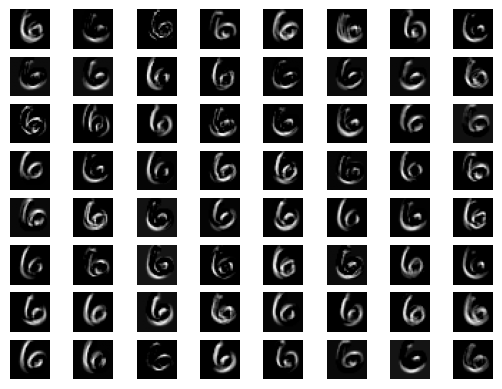

In [22]:
def show_images(images, cols = 1):
    n_images = len(images)
    fig = plt.figure()
    for n, image in enumerate(images):
        a = fig.add_subplot(cols, int(np.ceil(n_images/float(cols))), n + 1)
        plt.axis('off')
        if image.ndim == 2:
            plt.gray()
        plt.imshow(image)

# conversion features maps en images niveau de gris
images = []
for i in range(64):
  images.append(np.array(255*feature_maps[:,:,:,i]).reshape(28,28).astype('uint8'))

show_images(images, 8)

Les images obtenues semblent montrer que les filtres appris dans la première couche du réseau permettent la détection d'orientations ou des contours.



<h4>Visualisation des filtres</h4>

La visualisation des filtres de la couche d'entrée est relativement immédiate puisque que les filtres ont le même nombre de channels que les données d'entrée. Autrement dit, les filtres de la première couche sont définis sur le même domaine que les données.


In [23]:
# Récupère tous les paramètres appris par le réseau
weights = model2.get_weights()

for w in weights: print(w.shape)

(5, 5, 1, 64)
(64,)
(3, 3, 64, 128)
(128,)
(3, 3, 128, 128)
(128,)
(1152, 10)
(10,)


<b>A faire : </b> A quoi correspondent chaque ligne issues de l'affichage de la cellule précédente ?

(5, 5, 1, 64) : 64 filtres de taille 5×5 avec 1 canal d'entrée. Ils représentent les filtres de la première couche convolutionnelle.

(64,) : Le nombre de biais associés aux filtres de la première couche (64 biais).

(3, 3, 64, 128) : 128 filtres de convolution de taille 3×3 avec 64 canaux d'entrée. Ils représentent les filtres de la deuxième couche convolutionnelle.

(128,) : Le nombre de biais associés aux filtres de la deuxième couche (128 biais).

(3, 3, 128, 128) : 128 filtres de convolution de taille 3×3 avec 128 canaux d'entrée. Ils représentent les filtres de la troisième couche convolutionnelle.

(128,) : Le nombre de biais associés aux filtres de la troisième couche (128 biais).

(1152, 10) : Les 1152 poids d’entrées et 10 neurones de sortie. Elle représente les poids de la couche dense de classification.

(10,) : Le nombre de biais associés aux 10 neurones de sortie (10 biais).

Affichons maintenant les filtres de la première couche de convolution :

-0.24150021 0.16596462


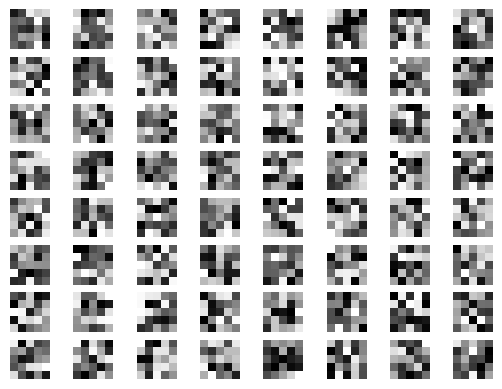

In [24]:
# normalize values between 0 and 1
minimum, maximum = np.min(weights[0]), np.max(weights[0])
weights0 = (weights[0] - minimum) / (maximum - minimum)

print(minimum, maximum)
# entre 0 et 255 pour l'affichage
weights0 *= 255.

images = []
for i in range(64):
  images.append(np.array(255*weights0[:,:,:,i]).reshape(5,5).astype('uint8'))

show_images(images, 8)

<h3> CNN pour des images naturelles </h3>

Les filtres de convolutions appris sur les données MNIST ne sont pas très parlantes, intéressons nous plutôt à un réseau (beaucoup plus profond) adapté à la classification d'images naturelles. Nous allons considérer pour cela le réseau VGG16, pré-entrainé sur le dataset ImageNet (cf cours).

In [25]:
# Récupération du modèle complet VGG16
model3 = VGG16(include_top=True, weights='imagenet')
print(model3.summary())

# chargement d'un dictionnaire qui met en correspondant l'index d'une classe ImageNet et son nom
with open('imagenet_class_index.json') as f:
    CLASS_INDEX = json.load(f)

# chargement et preprocess de l'image (dont normalisation et redimensionnement)
img_path = 'cat.jpg'
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

# prédiction et affichage de la classe de probabilité maximale
softmax_output = model3.predict(x)
best_class = np.argmax(softmax_output)
im_class = CLASS_INDEX[str(best_class)][1]
print("prediction: ", im_class)

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 51s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

None
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
prediction:  tiger_cat


Notre chaton a été reconnu comme un chat ? Alors tout va bien, et regardons les filtres de la première couche.

(3, 3, 3, 64)
(64,)
(3, 3, 64, 64)
(64,)
(3, 3, 64, 128)
(128,)
(3, 3, 128, 128)
(128,)
(3, 3, 128, 256)
(256,)
(3, 3, 256, 256)
(256,)
(3, 3, 256, 256)
(256,)
(3, 3, 256, 512)
(512,)
(3, 3, 512, 512)
(512,)
(3, 3, 512, 512)
(512,)
(3, 3, 512, 512)
(512,)
(3, 3, 512, 512)
(512,)
(3, 3, 512, 512)
(512,)
(25088, 4096)
(4096,)
(4096, 4096)
(4096,)
(4096, 1000)
(1000,)
-0.67140007 0.6085159


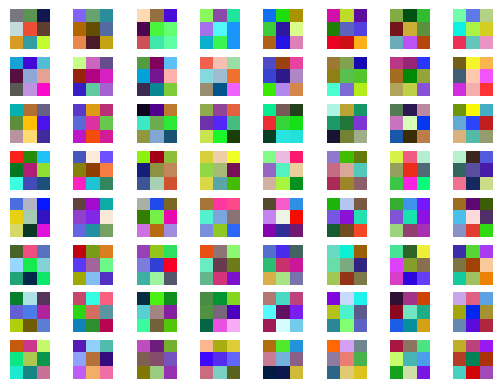

In [26]:
weights = model3.get_weights()
for w in weights: print(w.shape)

# normalize values between 0 and 1
minimum, maximum = np.min(weights[0]), np.max(weights[0])
weights0 = (weights[0] - minimum) / (maximum - minimum)

print(minimum, maximum)
# entre 0 et 255 pour l'affichage
weights0 *= 255.

images = []
for i in range(64):
  images.append(np.array(255*weights0[:,:,:,i]).reshape(3,3,3).astype('uint8'))

show_images(images, 8)

Notez qu'on affiche ici les fltres en RGB alors qu'on pourrait les afficher en séparant les channels. Dans tous les cas, cette visualisation reste peu informative. Pour mieux comprendre le rôle d'une couche de convolution, d'autres méthodes sont plus efficaces. Ci dessous, nous allons générer une image qui maximise la valeur d'une carte d'activation qui nous permettra d'interpréter ce que reconnait un filtre dans le domaine des pixels.



<h2> Entrainement d'un réseau plus profond </h2>

Un réseau très profond tel que VGG contient énormément de paramètres, son entrainement peu s'avérer compliqué. Tous les paramètres doivent entrer en mémoire (RAM ou GPU), ainsi que toutes les données d'un minibatch. Dans le cas d'images relativement volumineuses (ie: Imagenet =255x255x3), la taille du minibatch est souvent ainsi très couteux en mémoire et se voit ainsi réduit à quelques images, rendant l'entrainement encore plus long...

De plus, de grandes bases de données ne sont pas toujours disponibles. Dans ce cas, pour entrainer un tel réseau, plusieurs options sont possibles :
- partir d'un réseau déjà (pré-)entrainé, et/ou utiliser ses poids pour initialiser un autre réseau qui sera raffiné sur une base (réduite) d'images (= finetuning)
- régulariser les poids du réseau (peut aider mais ne suffit pas)
- augmenter artificiellement le nombre de données (améliore toujours les performances d'un réseau)

Dans la suite, nous illustrons ce dernier point sur les données MNIST.


In [27]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
img_rows, img_cols = 28, 28
num_classes = 10
nb_samples = len(x_train)
x_train = x_train.reshape(x_train.shape[0], img_rows, img_cols, 1)
x_test = x_test.reshape(x_test.shape[0], img_rows, img_cols, 1)
input_shape = (img_rows, img_cols, 1)
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255

# Sélection aléatoire de 5000 exemples
l_idx = list(range(nb_samples))
np.random.shuffle(l_idx)
l_idx = l_idx[:500]
x_train, y_train = x_train[l_idx], y_train[l_idx]

# conversion des étiquettes au format one-hot vector
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)


# Architecture du modèle
model2 = Sequential()
model2.add(Conv2D(64, kernel_size=(5,5), strides=(1,1), padding='same', activation='relu', input_shape=input_shape))
model2.add(MaxPooling2D((2,2)))
model2.add(Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same', activation='relu'))
model2.add(MaxPooling2D((2,2)))
model2.add(Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same', activation='relu'))
model2.add(MaxPooling2D((2,2)))
model2.add(Flatten())
model2.add(Dropout(0.2))
model2.add(Dense(num_classes, activation='softmax'))
model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

#print(model2.summary())

model2.fit(x_train, y_train, batch_size=128, epochs=20, verbose=1)

score = model2.evaluate(x_test, y_test, verbose=0)
print("score=", score)

c:\Users\felip\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 120ms/step - accuracy: 0.1560 - loss: 2.2734
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.3500 - loss: 2.1339
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5560 - loss: 1.8034
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.6880 - loss: 1.3132
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.7280 - loss: 0.8989
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.7760 - loss: 0.6607
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.8320 - loss: 0.5009
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8780 - loss: 0.4145
Epoch 9/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.8820 - loss: 0.3597
Epoch 10/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9100 - loss: 0.2683
Epoch 11/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9220 - loss: 0.2293
Epoch 12/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9260 - loss: 0.204

La performance obtenue peut être améliorée en augmentant les données. La cellule suivante génère 20000 données à partir des 5000 utilisées jusque là.



(128, 28, 28, 1) (128, 10)
Epoch 1/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.1880 - loss: 2.2836  
Epoch 2/20
  1/156 ━━━━━━━━━━━━━━━━━━━━ 22s 145ms/step - accuracy: 0.2500 - loss: 2.2330

c:\Users\felip\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2980 - loss: 2.1543  
Epoch 3/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4420 - loss: 1.8765  
Epoch 4/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6000 - loss: 1.4488   
Epoch 5/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6440 - loss: 1.1284  
Epoch 6/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6620 - loss: 0.9991  
Epoch 7/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7240 - loss: 0.8329  
Epoch 8/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7720 - loss: 0.7113  
Epoch 9/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7800 - loss: 0.6148   
Epoch 10/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8340 - loss: 0.4953   
Epoch 11/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8680 - loss: 0.4152   
Epoch 12/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8780 - loss: 0.3737   
Epoch 13/20
156/156 ━━━━━━━━━━━━━━━

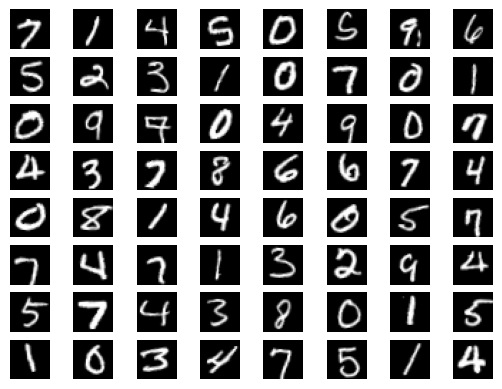

In [28]:
# déclaration d'un générateur, qui transformera "à la volée" des données MNIST
datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range = 0.05,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=False, # flip horizontal et vertical n'ont pas de sens pour des digits !
    vertical_flip=False
    )
datagen.fit(x_train)

# On instancie le générateur
flow = datagen.flow(x_train, y_train, batch_size=128, shuffle=True)

# Pour affichage : une itération du générateur
xx = next(flow)
print(xx[0].shape, xx[1].shape)

images = []
for i in range(64):
  images.append(np.array(255*xx[0][i,:,:,:]).reshape(28,28).astype('uint8'))
show_images(images, 8)


# réinitialisation du modèle
model2 = Sequential()
model2.add(Conv2D(64, kernel_size=(5,5), strides=(1,1), padding='same', activation='relu', input_shape=input_shape))
model2.add(MaxPooling2D((2,2)))
model2.add(Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same', activation='relu'))
model2.add(MaxPooling2D((2,2)))
model2.add(Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same', activation='relu'))
model2.add(MaxPooling2D((2,2)))
model2.add(Flatten())
model2.add(Dropout(0.2))
model2.add(Dense(num_classes, activation='softmax'))
model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# entrainement avec les données augmentées (à la volée)
#model2.fit_generator(datagen.flow(x_train, y_train, batch_size=128), steps_per_epoch=int(20000/128), epochs=20)
model2.fit(flow, steps_per_epoch=int(20000/128), epochs=20)

# évaluation
score = model2.evaluate(x_test, y_test, verbose=0)
print("score=", score)


<b>A faire : </b> testez d'autres formes d'augmentation et d'autres quantités pour constater l'impact sur la précision du réseau.

(128, 28, 28, 1) (128, 10)
Epoch 1/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.1700 - loss: 2.2783  
Epoch 2/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3300 - loss: 2.1361  
Epoch 3/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5540 - loss: 1.8276   
Epoch 4/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6520 - loss: 1.3475  
Epoch 5/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7100 - loss: 0.9311   
Epoch 6/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7240 - loss: 0.7800  
Epoch 7/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7700 - loss: 0.6449  
Epoch 8/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8340 - loss: 0.5218  
Epoch 9/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8340 - loss: 0.4552  
Epoch 10/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8960 - loss: 0.3575  
Epoch 11/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8860 - loss: 0.3284   


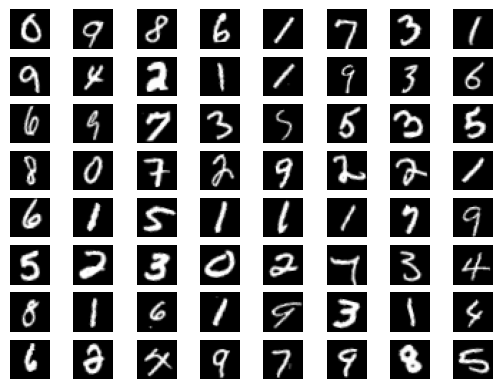

In [29]:
# déclaration d'un générateur, qui transformera "à la volée" des données MNIST
datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range = 0.01,
    width_shift_range=0.01,
    height_shift_range=0.01,
    horizontal_flip=False, # flip horizontal et vertical n'ont pas de sens pour des digits !
    vertical_flip=False
    )
datagen.fit(x_train)

# On instancie le générateur
flow = datagen.flow(x_train, y_train, batch_size=128, shuffle=True)

# Pour affichage : une itération du générateur
xx = next(flow)
print(xx[0].shape, xx[1].shape)

images = []
for i in range(64):
  images.append(np.array(255*xx[0][i,:,:,:]).reshape(28,28).astype('uint8'))
show_images(images, 8)


# réinitialisation du modèle
model2 = Sequential()
model2.add(Conv2D(64, kernel_size=(5,5), strides=(1,1), padding='same', activation='relu', input_shape=input_shape))
model2.add(MaxPooling2D((2,2)))
model2.add(Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same', activation='relu'))
model2.add(MaxPooling2D((2,2)))
model2.add(Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same', activation='relu'))
model2.add(MaxPooling2D((2,2)))
model2.add(Flatten())
model2.add(Dropout(0.2))
model2.add(Dense(num_classes, activation='softmax'))
model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# entrainement avec les données augmentées (à la volée)
#model2.fit_generator(datagen.flow(x_train, y_train, batch_size=128), steps_per_epoch=int(20000/128), epochs=20)
model2.fit(flow, steps_per_epoch=int(20000/128), epochs=20)

# évaluation
score = model2.evaluate(x_test, y_test, verbose=0)
print("score=", score)


<b>A faire : </b> modifiez l'architecture pour la classification d'images naturelles et appliquez le au jeu de données Cifar10.

In [31]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1420s 8us/step


In [32]:
model_cifar = Sequential()

model_cifar.add(Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)))
model_cifar.add(MaxPooling2D((2,2)))
model_cifar.add(Conv2D(64, (3,3), activation='relu', padding='same'))
model_cifar.add(MaxPooling2D((2,2)))
model_cifar.add(Flatten())
model_cifar.add(Dense(10, activation='softmax'))

model_cifar.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

c:\Users\felip\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
model_cifar.fit(x_train, y_train, batch_size=128, epochs=10, validation_split=0.1)


score = model_cifar.evaluate(x_test, y_test, verbose=0)
print("score=", score)

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.4333 - loss: 1.5996 - val_accuracy: 0.5420 - val_loss: 1.3346
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.5737 - loss: 1.2282 - val_accuracy: 0.6086 - val_loss: 1.1544
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.6256 - loss: 1.0857 - val_accuracy: 0.6358 - val_loss: 1.0556
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.6545 - loss: 1.0013 - val_accuracy: 0.6310 - val_loss: 1.0521
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - accuracy: 0.6752 - loss: 0.9414 - val_accuracy: 0.6772 - val_loss: 0.9527
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.6930 - loss: 0.8916 - val_accuracy: 0.6808 - val_loss: 0.9444
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.7089 - loss: 0.8553 - val_accuracy: 0.6910 - val_loss: 0.9196
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.7170 - loss: 0.8235 - 

In [ ]:
model_cifar = Sequential()

model_cifar.add(Conv2D(64, (3,3), activation='relu', padding='same', input_shape=(32,32,3)))
model_cifar.add(MaxPooling2D((2,2)))

model_cifar.add(Conv2D(64, (3,3), activation='relu', padding='same'))
model_cifar.add(MaxPooling2D((2,2)))

model_cifar.add(Conv2D(128, (3,3), activation='relu', padding='same'))
model_cifar.add(MaxPooling2D((2,2)))

model_cifar.add(Conv2D(128, (3,3), activation='relu', padding='same'))
model_cifar.add(MaxPooling2D((2,2)))

model_cifar.add(Conv2D(128, (3,3), activation='relu', padding='same'))
model_cifar.add(MaxPooling2D((2,2)))

model_cifar.add(Flatten())
model_cifar.add(Dense(120, activation='relu'))
model_cifar.add(Dropout(0.25))

model_cifar.add(Dense(84, activation='relu'))
model_cifar.add(Dropout(0.15))

model_cifar.add(Dense(10, activation='softmax'))

model_cifar.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

c:\Users\felip\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model_cifar.fit(x_train, y_train, batch_size=128, epochs=10, validation_split=0.1)


score = model_cifar.evaluate(x_test, y_test, verbose=0)
print("score=", score)


Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 35s 89ms/step - accuracy: 0.3310 - loss: 1.7727 - val_accuracy: 0.4906 - val_loss: 1.3594
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 29s 81ms/step - accuracy: 0.5272 - loss: 1.2959 - val_accuracy: 0.5964 - val_loss: 1.1000
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 29s 82ms/step - accuracy: 0.6142 - loss: 1.0778 - val_accuracy: 0.6564 - val_loss: 0.9833
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 34s 96ms/step - accuracy: 0.6791 - loss: 0.9200 - val_accuracy: 0.6938 - val_loss: 0.8727
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.7247 - loss: 0.8061 - val_accuracy: 0.7282 - val_loss: 0.8092
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 30s 87ms/step - accuracy: 0.7575 - loss: 0.7075 - val_accuracy: 0.7206 - val_loss: 0.8046
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 35s 97ms/step - accuracy: 0.7873 - loss: 0.6247 - val_accuracy: 0.7434 - val_loss: 0.8064
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 35s 98ms/step - accuracy: 0.8137 - loss: 0.5467 - 